In [1]:
import duckdb
con = duckdb.connect("../data/power.duckdb", read_only=True)
con.sql("SET Timezone = 'UTC'")

SuccessBOOLEAN


In [2]:
savings = con.sql("""
WITH nights AS (
    --Step 1: We keep only the hours the car is at home (18:00 to 7:00
    -- and label each hour with the evening it belongs it 
    SELECT
        CAST(ts_local - INTERVAL 7 HOUR AS DATE) AS night,
        hour,
        price_euro_mwh
    FROM features
    WHERE hour >= 18 OR hour <7
),
per_night AS (
    -- Step 2: for each night, the price at 18:00 and the cheapest price
    SELECT
        night,
        MAX(price_euro_mwh)FILTER (WHERE hour = 18) AS price_at_18,
        MIN(price_euro_mwh)                          AS price_cheapest_night
    FROM nights
    GROUP BY night
    HAVING COUNT(*) >= 12          -- complete nights only
),
per_day AS (
    -- Step 3: the cheapest hour of each whole day
    SELECT
        CAST(ts_local AS DATE) AS day,
        MIN(price_euro_mwh)    AS price_cheapest_day
    FROM features
    GROUP BY day
),
per_year AS (
    -- Step 4: add up the cost of 10 kWh per day, per year
    SELECT
        year(n.night)                             AS year,
        COUNT(*)                                  AS n_days,
        SUM(n.price_at_18)          * 10 / 1000   AS cost_plug_in,
        SUM(n.price_cheapest_night) * 10 / 1000   AS cost_smart_night,
        SUM(d.price_cheapest_day)   * 10 / 1000   AS cost_best_hour
    FROM per_night AS n
    JOIN per_day AS d
        ON n.night = d.day
    GROUP BY year
)
SELECT
    year,
    n_days,
    ROUND(cost_plug_in, 0)                       AS cost_plug_in_eur,
    ROUND(cost_smart_night, 0)                   AS cost_smart_night_eur,
    ROUND(cost_best_hour, 0)                     AS cost_best_hour_eur,
    ROUND(cost_plug_in - cost_smart_night, 0)    AS saving_smart_night_eur,
    ROUND(cost_plug_in - cost_best_hour, 0)      AS saving_best_hour_eur
FROM per_year
ORDER BY year
""").df()

savings


,year,n_days,cost_plug_in_eur,cost_smart_night_eur,cost_best_hour_eur,saving_smart_night_eur,saving_best_hour_eur
0,2018,92,62.0,32.0,30.0,29.0,31.0
1,2019,365,170.0,95.0,85.0,75.0,86.0
2,2020,366,147.0,74.0,56.0,74.0,92.0
3,2021,365,450.0,249.0,215.0,201.0,234.0
4,2022,365,1080.0,668.0,546.0,412.0,534.0
5,2023,365,451.0,267.0,186.0,184.0,264.0
6,2024,366,402.0,222.0,121.0,181.0,281.0
7,2025,365,453.0,277.0,127.0,176.0,326.0
8,2026,300,448.0,317.0,107.0,131.0,341.0


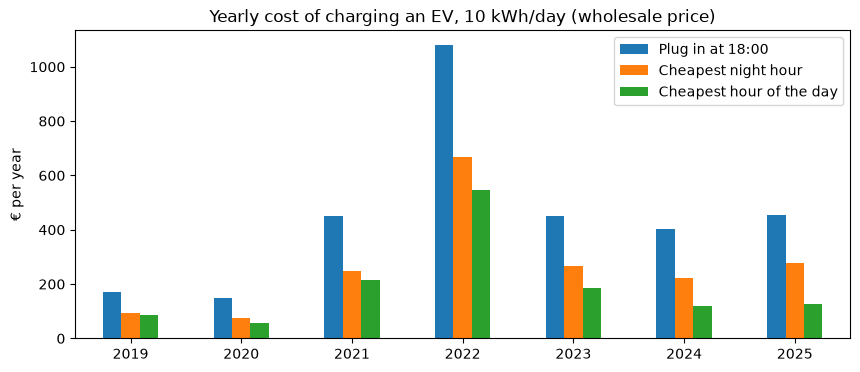

In [6]:
ax = full_years[["cost_plug_in_eur", "cost_smart_night_eur", "cost_best_hour_eur"]].plot(
    kind="bar",
    figsize=(10, 4),
    title="Yearly cost of charging an EV, 10 kWh/day (wholesale price)",
)
ax.set_ylabel("€ per year")
ax.set_xlabel("")
ax.legend(["Plug in at 18:00", "Cheapest night hour", "Cheapest hour of the day"])
ax.tick_params(axis="x", rotation=0)

## EV charging savings (10 kWh/day, wholesale price only)

Assumptions: 10 kWh per day, 11 kW wallbox (about 1 hour), car at home
18:00–07:00. Taxes and grid fees are the same every hour, so they don't
change the savings.

- Smart night charging (cheapest hour 18:00–07:00) saved 38–50% every year
  compared with plugging in at 18:00. In 2025: €176 per year (39%).
- Charging at the cheapest hour of the whole day saved even more, and the
  gap is growing: €86 in 2019, €326 in 2025 (72%). The cheapest hours have
  moved from night to midday because of solar.
- 2022 (energy crisis) was the most expensive year: €1,080 to charge at
  18:00, €412 saved by smart night charging.
- No forecast is needed for this: next-day prices are published around
  13:00, before the car is plugged in. A forecast matters for decisions
  made earlier (Step 10).
  

In [ ]:
con.close()